#Librerias

In [45]:
import warnings
warnings.filterwarnings('ignore')

# Manejo de datos
import pandas as pd
import numpy as np

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Regresión logística (resumen con coeficientes y p-valores)
import statsmodels.api as sm

# Separación train/test y búsqueda de hiperparámetros
from sklearn.model_selection import train_test_split, GridSearchCV

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
# Mostrar todas las columnas al imprimir tablas
pd.set_option('display.max_columns', None)

#Carga de datos

In [46]:
# El Excel debe estar en la misma carpeta que este notebook
df_original = pd.read_excel('base_de_datos_medicina_complicaciones_modificada.xlsx')

# Trabajamos sobre una copia para no alterar el original
df = df_original.copy()

print(df.shape)
df.head(3)

(10000, 41)


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,Maestria,Nivel 2 - Pobreza,Oruro,Oruro,"Zona Sur, Calle 33, Av. 196",75137722,Instituto de Seguros Sociales (CNS),Unidad de Salud,05/03/2024,Hernia Discal; Vacunacion; Infecciones Urinarias,Orina Frecuente; Erupcion Cutanea; Ganancia de...,A+,134.7,115.3,101.3,100/104,58,37.4,212,219,320,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...


#Entendimiento del negocio

##1. ¿Qué problema aborda el proyecto?

**Problema:** en la base de pacientes, 8,782 de 10,000 (87.82 %) presentaron alguna complicación médica (sepsis, hemorragia, embolia, infección nosocomial, reacción adversa, fallo multiorgánico). Es una prevalencia muy alta.

**Decisión que apoya:** identificar a los pacientes con mayor riesgo de complicación para priorizar un programa de prevención y seguimiento.

**Criterio de éxito de negocio:** reducir la prevalencia de complicaciones del 87.82 % actual a un máximo de 75 %.

**A quién afecta:** a los pacientes, que sufren las complicaciones, y al hospital, por los costos de hospitalización y de atención.

**Conexión con el análisis:** el análisis crea un modelo de clasificación que, con datos del paciente, predice si tendrá o no una complicación (1 = con complicación, 0 = "Ninguna"). Esa predicción permite actuar antes de que ocurra.

##2. Métrica principal del proyecto

**Métrica de negocio (principal): Prevalencia de complicaciones**

Prevalencia = (Pacientes con alguna complicación / Total de pacientes) × 100

- Variables: pacientes con complicación (conteo de pacientes) y total de pacientes (conteo de pacientes).
- Unidad: porcentaje (%).
- Valor observado: **87.82 %** (línea base).
- Meta: ≤ 75 %.

**Métrica de desempeño del modelo: Recall (sensibilidad)**

Recall = TP / (TP + FN), con meta ≥ 0.70. Su valor obtenido se reporta en la Pregunta 9.

**Acción concreta para mejorarla:** aplicar el protocolo de prevención (controles adicionales y medidas preventivas) a los pacientes que el modelo clasifique como de alto riesgo, y medir si la prevalencia baja hacia el 75 %.

In [47]:
# Variable objetivo: 1 = con complicación, 0 = sin complicación ("Ninguna")
df['TARGET_COMPLICACION'] = (df['COMPLICACIONES'] != 'Ninguna').astype(int)

total_pacientes = df.shape[0]
con_complicacion = df['TARGET_COMPLICACION'].sum()
prevalencia = con_complicacion / total_pacientes * 100

print(f'Pacientes con complicación: {con_complicacion} de {total_pacientes}')
print(f'Prevalencia: {prevalencia:.2f}%')

Pacientes con complicación: 8782 de 10000
Prevalencia: 87.82%


#Entendimiento y preparación de los datos

##3. Unidad de análisis, origen y tamaño de los datos

- **Unidad de análisis:** un paciente. Cada fila es el registro de un paciente, con sus datos demográficos, clínicos, de laboratorio y de tratamiento. Los 10,000 números de registro y las 10,000 cédulas son únicos, así que ningún paciente aparece dos veces.
- **Origen:** archivo Excel `base_de_datos_medicina_complicaciones_modificada.xlsx`. Según la columna `OBSERVACIONES`, los registros fueron generados automáticamente por el Banco Nacional de Salud de Bolivia. Cubren pacientes registrados entre 2020 y 2024 en los 9 departamentos del país.
- **Tamaño:** 10,000 registros y 41 variables (27 de texto, 8 enteras y 6 decimales).
- **Filtros aplicados:** ninguno. Se usaron los 10,000 registros, por lo que después de la preparación siguen siendo 10,000.
- **Variable objetivo:** `COMPLICACIONES`, que se convierte en binaria (1 = con complicación, 0 = "Ninguna").

In [48]:
print("Registros (filas):", df.shape[0])
print("Variables (columnas):", df.shape[1])

print("\nTipos de variables:")
print(df.dtypes.value_counts())

print("\nNRO_REGISTRO únicos:", df['NRO_REGISTRO'].nunique())
print("CI_PACIENTE únicos:", df['CI_PACIENTE'].nunique())

print("\nOrigen de los registros:")
print(df['OBSERVACIONES'].unique())

print("\nRegistros por año:")
print(df['FECHA_REGISTRO'].str[-4:].value_counts().sort_index())

df.head(3)

Registros (filas): 10000
Variables (columnas): 42

Tipos de variables:
object     27
int64       8
float64     6
int32       1
Name: count, dtype: int64

NRO_REGISTRO únicos: 10000
CI_PACIENTE únicos: 10000

Origen de los registros:
['Registro generado automaticamente por el Banco Nacional de Salud de Bolivia']

Registros por año:
FECHA_REGISTRO
2020    2064
2021    1978
2022    2031
2023    2029
2024    1898
Name: count, dtype: int64


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES,TARGET_COMPLICACION
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...,1
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...,1
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,Maestria,Nivel 2 - Pobreza,Oruro,Oruro,"Zona Sur, Calle 33, Av. 196",75137722,Instituto de Seguros Sociales (CNS),Unidad de Salud,05/03/2024,Hernia Discal; Vacunacion; Infecciones Urinarias,Orina Frecuente; Erupcion Cutanea; Ganancia de...,A+,134.7,115.3,101.3,100/104,58,37.4,212,219,320,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...,1


##4. Calidad de los datos y preparación aplicada

**Valores faltantes:** solo la columna `IMC` tiene valores faltantes: 9,918 de 10,000 registros no nulos, es decir, 82 faltantes (0.82 %). Las otras 40 columnas están completas.

**Duplicados:** no hay filas duplicadas; los 10,000 `NRO_REGISTRO` y `CI_PACIENTE` son únicos.

**Inconsistencias:** `describe()` muestra valores extremos poco realistas, como un IMC máximo de 418, una estatura mínima de 45.3 cm y un peso mínimo de 2.6 kg junto a edades de 0 a 95 años.

**Preparación aplicada:**
- Las variables categóricas `SEXO` y `DEPARTAMENTO` se convirtieron a variables dummy (`drop_first=True`) y luego a enteros, para poder usarlas en los modelos.
- `IMC` no se imputó ni se eliminó, porque no se usa como variable predictora en el modelo (solo `EDAD`, `GLUCEMIA`, `SEXO` y `DEPARTAMENTO`).
- No se eliminaron registros: se usaron los 10,000.

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 42 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  object 
 1   CI_PACIENTE            10000 non-null  object 
 2   NOMBRE                 10000 non-null  object 
 3   APELLIDO1              10000 non-null  object 
 4   APELLIDO2              10000 non-null  object 
 5   SEXO                   10000 non-null  object 
 6   FECHA_NACIMIENTO       10000 non-null  object 
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  object 
 9   OCUPACION              10000 non-null  object 
 10  NIVEL_EDUCATIVO        10000 non-null  object 
 11  NIVEL_SOCIOECONOMICO   10000 non-null  object 
 12  DEPARTAMENTO           10000 non-null  object 
 13  CAPITAL_DEPTO          10000 non-null  object 
 14  DIRECCION              10000 non-null  object 
 15  TEL

In [50]:
df.describe()

,EDAD,TELEFONO,PESO_KG,ESTATURA_CM,IMC,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION,NUMERO_CONTROLES,TARGET_COMPLICACION
count,10000.000000,1.000000e+04,10000.000000,10000.000000,9918.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,46.936200,7.548072e+07,91.570390,145.582480,51.425711,84.857200,38.012810,180.301300,199.838900,224.719900,13.023410,2.649961,1.794100,6.001700,0.878200
std,27.547588,2.594845e+06,33.485332,34.600805,39.324128,20.294507,1.449198,69.114544,58.439698,101.269021,2.896742,1.354487,5.810911,3.765251,0.327071
min,0.000000,7.100100e+07,2.600000,45.300000,0.700000,50.000000,35.500000,60.000000,100.000000,50.000000,8.000000,0.300000,0.000000,0.000000,0.000000
25%,23.000000,7.324466e+07,64.475000,120.800000,28.000000,67.000000,36.800000,121.000000,149.000000,136.000000,10.500000,1.500000,0.000000,3.000000,1.000000
50%,47.000000,7.541180e+07,92.000000,147.400000,41.000000,85.000000,38.000000,181.000000,200.000000,225.000000,13.100000,2.630000,0.000000,6.000000,1.000000
75%,71.000000,7.774810e+07,119.200000,174.125000,62.775000,102.250000,39.300000,239.000000,251.000000,312.000000,15.600000,3.820000,0.000000,9.000000,1.000000
max,95.000000,7.999966e+07,150.000000,200.000000,418.000000,120.000000,40.500000,300.000000,300.000000,400.000000,18.000000,5.000000,30.000000,12.000000,1.000000


#Exploración de los datos

##5. Resultado interesante de la exploración

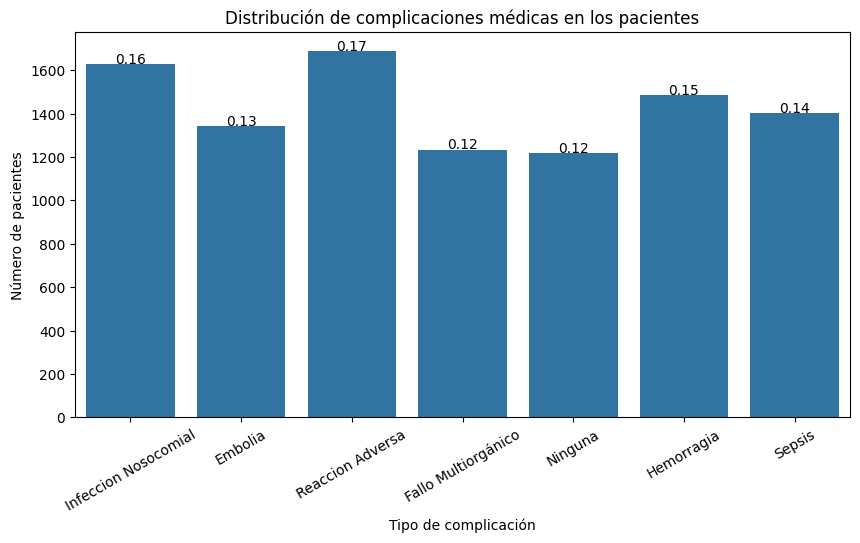

In [51]:
plt.figure(figsize=(10, 5))                      # AÑADIDO: gráfico más ancho
ax = sns.countplot(x='COMPLICACIONES', data=df)
total = float(len(df))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}'.format(height/total),
            ha="center")
plt.title('Distribución de complicaciones médicas en los pacientes')   # AÑADIDO
plt.xlabel('Tipo de complicación')                                     # AÑADIDO
plt.ylabel('Número de pacientes')                                      # AÑADIDO
plt.xticks(rotation=30)                                                # AÑADIDO: evita que se encimen los nombres
plt.show()

In [52]:
df['COMPLICACIONES'].value_counts()

COMPLICACIONES
Reaccion Adversa        1690
Infeccion Nosocomial    1627
Hemorragia              1486
Sepsis                  1401
Embolia                 1344
Fallo Multiorgánico     1234
Ninguna                 1218
Name: count, dtype: int64

**Patrón observado:** la categoría "Ninguna" (pacientes sin complicación) es la más pequeña: solo 1,218 de 10,000 pacientes (12.18 %). El 87.82 % restante presenta alguna complicación, repartida de forma bastante pareja entre seis tipos, de Reacción Adversa (16.90 %, la más frecuente) a Fallo Multiorgánico (12.34 %). Ningún tipo domina.

**Por qué importa para el objetivo:**
1. Confirma el problema de negocio: casi 9 de cada 10 pacientes sufren una complicación, muy por encima de la meta del 75 %.
2. Muestra un fuerte desbalance de clases (88 % con complicación contra 12 % sin ella). Un modelo que prediga siempre "con complicación" ya tendría una exactitud del 87.8 %, sin haber aprendido nada. Por eso, para evaluar el modelo no basta la exactitud y hay que mirar también recall, precisión y F1.

#Modelado

##6. Variable objetivo y modelo utilizado

In [53]:
# Variable objetivo binaria (la misma de h3_1 y h3_2)
# 1 = paciente con alguna complicación, 0 = sin complicación ("Ninguna")
df['TARGET_COMPLICACION'] = (df['COMPLICACIONES'] != 'Ninguna').astype(int)

print("Conteo:")
print(df['TARGET_COMPLICACION'].value_counts())
print("\nProporción:")
print(df['TARGET_COMPLICACION'].value_counts(normalize=True))

Conteo:
TARGET_COMPLICACION
1    8782
0    1218
Name: count, dtype: int64

Proporción:
TARGET_COMPLICACION
1    0.8782
0    0.1218
Name: proportion, dtype: float64


**Variable objetivo:** `TARGET_COMPLICACION`, creada a partir de la columna `COMPLICACIONES`. Es una variable binaria con dos clases:
- **0 = Sin complicación** (valor "Ninguna"): 1,218 pacientes (12.18 %).
- **1 = Con complicación** (cualquiera de los otros seis tipos): 8,782 pacientes (87.82 %).

**Modelos utilizados:** se usaron **ambos modelos revisados en clase**: regresión logística y árbol de decisión, con las mismas variables predictoras (`EDAD`, `GLUCEMIA`, `SEXO` y `DEPARTAMENTO`) y la misma partición de datos.

**Por qué son pertinentes:**
- El problema es de **clasificación binaria** (¿tendrá o no una complicación?), que es el caso para el que sirven ambos modelos.
- La **regresión logística** entrega la probabilidad de complicación y sus coeficientes permiten interpretar cómo se asocia cada variable con el riesgo.
- El **árbol de decisión** produce reglas "si... entonces..." que se pueden leer y explicar a personal médico sin conocimientos de estadística.
- Se eligió trabajar con ambos para comparar un modelo lineal con uno basado en reglas. El árbol se ajustó con `GridSearchCV` usando Recall como criterio, porque es la métrica técnica del proyecto (meta: Recall ≥ 0.70).

#Modelado (continuación)

##7. Partición en entrenamiento y prueba

In [54]:
from sklearn.model_selection import train_test_split

# Variables predictoras: EDAD, GLUCEMIA y las dummies de SEXO y DEPARTAMENTO
columnas_modelo = ['EDAD', 'GLUCEMIA']
columnas_modelo += [c for c in df.columns
                    if c.startswith('SEXO_') or c.startswith('DEPARTAMENTO_')]

X = df[columnas_modelo].copy()
y = df['TARGET_COMPLICACION']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=777,
    stratify=y
)

print("Tamaño TRAIN:", X_train.shape)
print("Tamaño TEST :", X_test.shape)

Tamaño TRAIN: (8000, 2)
Tamaño TEST : (2000, 2)


In [55]:
print("TRAIN:", y_train.value_counts().to_dict())
print("TEST :", y_test.value_counts().to_dict())

print("\nProporción de complicación en TRAIN:", y_train.mean())
print("Proporción de complicación en TEST :", y_test.mean())

print("\nLo que se esperaba con 80 %:")
print("Con complicación:", 8782 * 0.8, "| Sin complicación:", 1218 * 0.8)

TRAIN: {1: 7026, 0: 974}
TEST : {1: 1756, 0: 244}

Proporción de complicación en TRAIN: 0.87825
Proporción de complicación en TEST : 0.878

Lo que se esperaba con 80 %:
Con complicación: 7025.6 | Sin complicación: 974.4000000000001


In [56]:
# 1) Ningún registro está en los dos conjuntos
interseccion = set(X_train.index) & set(X_test.index)
print("Registros en ambos conjuntos:", len(interseccion))

# 2) Entre los dos conjuntos están los 10,000 registros, ni más ni menos
print("Total de registros cubiertos:", len(set(X_train.index) | set(X_test.index)))

# 3) Ningún paciente aparece en ambos conjuntos
ci_train = set(df.loc[X_train.index, 'CI_PACIENTE'])
ci_test = set(df.loc[X_test.index, 'CI_PACIENTE'])
print("Pacientes (CI) en ambos conjuntos:", len(ci_train & ci_test))

Registros en ambos conjuntos: 0
Total de registros cubiertos: 10000
Pacientes (CI) en ambos conjuntos: 0


In [57]:
print("Pacientes SIN complicación en TEST, según la semilla")
print(f"{'semilla':>8} | {'sin stratify':>12} | {'con stratify':>12}")
for semilla in [777, 1, 2, 3]:
    _, _, _, y_te_sin = train_test_split(X, y, test_size=0.20, random_state=semilla)
    _, _, _, y_te_con = train_test_split(X, y, test_size=0.20, random_state=semilla, stratify=y)
    print(f"{semilla:>8} | {(y_te_sin == 0).sum():>12} | {(y_te_con == 0).sum():>12}")

Pacientes SIN complicación en TEST, según la semilla
 semilla | sin stratify | con stratify
     777 |          261 |          244
       1 |          237 |          244
       2 |          247 |          244
       3 |          231 |          244


**Proporción:** 80 % para entrenamiento (8,000 pacientes) y 20 % para prueba (2,000 pacientes).

**Método:** `train_test_split` de scikit-learn con `test_size=0.20`, `random_state=777` (partición reproducible) y `stratify=y`. La estratificación mantiene la proporción de clases en ambos conjuntos: entrenamiento con 7,026 con complicación y 974 sin ella (87.83 % y 12.18 %), y prueba con 1,756 y 244 (87.8 % y 12.2 %). Se comprobó que, sin estratificar, el número de pacientes sin complicación en la prueba varía entre 231 y 261 según la semilla, mientras que con estratificación es siempre 244.

**Cómo se evitó que la prueba influyera en el entrenamiento:**
- Se comprobó que no hay registros ni pacientes (`CI_PACIENTE`) en ambos conjuntos: la intersección es 0 y entre los dos conjuntos suman los 10,000 registros.
- Los modelos se entrenaron solo con `X_train` y `y_train`.
- Los hiperparámetros del árbol se buscaron con `GridSearchCV` (`cv=5`) únicamente dentro del conjunto de entrenamiento.
- El umbral de clasificación se fijó de antemano en 0.50, sin ajustarlo con la prueba.
- La única preparación fue codificar `SEXO` y `DEPARTAMENTO` como dummies, una transformación fija que no calcula estadísticos a partir de los datos (no hay escalado ni imputación), así que no transmite información de la prueba.
- El conjunto de prueba se usó solo para evaluar.

##8. Variables más importantes

In [58]:
import statsmodels.api as sm

X_train_const = sm.add_constant(X_train.astype(float), has_constant='add')
modelo_logit = sm.Logit(y_train.astype(int), X_train_const).fit()
print(modelo_logit.summary())

Optimization terminated successfully.
         Current function value: 0.370255
         Iterations 6
                            Logit Regression Results                           
Dep. Variable:     TARGET_COMPLICACION   No. Observations:                 8000
Model:                           Logit   Df Residuals:                     7997
Method:                            MLE   Df Model:                            2
Date:                 Fri, 09 Oct 2026   Pseudo R-squ.:               0.0003838
Time:                         14:49:36   Log-Likelihood:                -2962.0
converged:                        True   LL-Null:                       -2963.2
Covariance Type:             nonrobust   LLR p-value:                    0.3207
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.8841      0.112     16.841      0.000       1.665       2.103
EDAD           0.0019

In [59]:
import numpy as np

tabla_logit = pd.DataFrame({
    'coeficiente': modelo_logit.params,
    'odds_ratio': np.exp(modelo_logit.params),
    'p_valor': modelo_logit.pvalues
}).drop(index='const')

tabla_logit = tabla_logit.reindex(
    tabla_logit['coeficiente'].abs().sort_values(ascending=False).index
)
print(tabla_logit.round(4))

          coeficiente  odds_ratio  p_valor
EDAD           0.0019      1.0019   0.1318
GLUCEMIA       0.0000      1.0000   0.9552


In [60]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    'max_depth': list(range(3, 15)),
    'min_samples_split': list(range(2, 10)),
    'min_samples_leaf': list(range(1, 5))
}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=777),
    param_grid, scoring='recall', cv=5
)
grid_search.fit(X_train, y_train)
print("Mejores hiperparámetros:", grid_search.best_params_)

modelo_ArbolDecisionClasif = grid_search.best_estimator_

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': modelo_ArbolDecisionClasif.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df.round(4))
print("\nSuma de importancias:", importance_df['Importance'].sum())

Mejores hiperparámetros: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
    Feature  Importance
0      EDAD      0.5551
1  GLUCEMIA      0.4449

Suma de importancias: 1.0


In [61]:
usadas = X_train.columns[
    sorted(set(modelo_ArbolDecisionClasif.tree_.feature[
        modelo_ArbolDecisionClasif.tree_.feature >= 0]))
].tolist()
print("Variables que el árbol usa en sus divisiones:", usadas)
print("Profundidad:", modelo_ArbolDecisionClasif.get_depth(),
      "| Hojas:", modelo_ArbolDecisionClasif.get_n_leaves())

Variables que el árbol usa en sus divisiones: ['EDAD', 'GLUCEMIA']
Profundidad: 3 | Hojas: 7


In [62]:
# Convertir SEXO y DEPARTAMENTO a variables dummy (solo si aún no se hizo)
if 'SEXO' in df.columns:
    df = pd.get_dummies(df, columns=['SEXO', 'DEPARTAMENTO'], drop_first=True)
    for col in df.columns:
        if col.startswith('SEXO_') or col.startswith('DEPARTAMENTO_'):
            df[col] = df[col].astype(int)

print(df.shape)
print([c for c in df.columns if c.startswith('SEXO') or c.startswith('DEPARTAMENTO')])

(10000, 49)
['SEXO_M', 'DEPARTAMENTO_Chuquisaca', 'DEPARTAMENTO_Cochabamba', 'DEPARTAMENTO_La Paz', 'DEPARTAMENTO_Oruro', 'DEPARTAMENTO_Pando', 'DEPARTAMENTO_Potosí', 'DEPARTAMENTO_Santa Cruz', 'DEPARTAMENTO_Tarija']


##9. Desempeño del modelo en el conjunto de prueba

Matriz Logit:
 [[   0  244]
 [   0 1756]]
Matriz Árbol:
 [[   0  244]
 [   0 1756]]


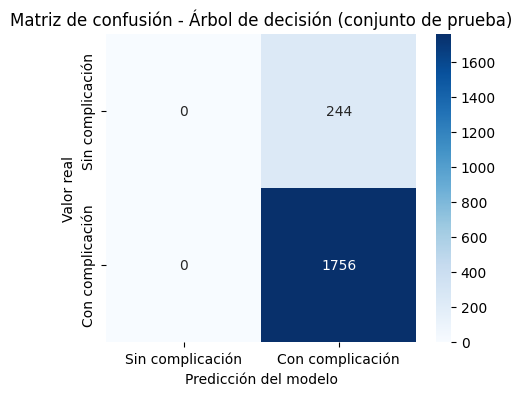

In [63]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

# Regresión logística (umbral 0.50)
X_test_const = sm.add_constant(X_test.astype(float), has_constant='add')
prob_logit = modelo_logit.predict(X_test_const)
pred_logit = (prob_logit >= 0.50).astype(int)

# Árbol de decisión (umbral 0.50)
prob_tree = modelo_ArbolDecisionClasif.predict_proba(X_test)[:, 1]
pred_tree = (prob_tree >= 0.50).astype(int)

cm_logit = confusion_matrix(y_test, pred_logit)
cm_tree = confusion_matrix(y_test, pred_tree)
print("Matriz Logit:\n", cm_logit)
print("Matriz Árbol:\n", cm_tree)

# Gráfico de la matriz del árbol
plt.figure(figsize=(5, 4))
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sin complicación', 'Con complicación'],
            yticklabels=['Sin complicación', 'Con complicación'])
plt.title('Matriz de confusión - Árbol de decisión (conjunto de prueba)')
plt.xlabel('Predicción del modelo')
plt.ylabel('Valor real')
plt.show()

In [64]:
for nombre, cm, prob, pred in [("Logit", cm_logit, prob_logit, pred_logit),
                               ("Árbol", cm_tree, prob_tree, pred_tree)]:
    TN, FP, FN, TP = cm.ravel()
    print(f"--- {nombre} ---")
    print("Accuracy   =", (TP + TN) / cm.sum(), "->", f"({TP}+{TN})/{cm.sum()}")
    print("Precisión  =", TP / (TP + FP), "->", f"{TP}/({TP}+{FP})")
    print("Recall     =", TP / (TP + FN), "->", f"{TP}/({TP}+{FN})")
    print("Especificidad =", TN / (TN + FP), "->", f"{TN}/({TN}+{FP})")
    print("F1         =", f1_score(y_test, pred))
    print("ROC-AUC    =", round(roc_auc_score(y_test, prob), 4))

--- Logit ---
Accuracy   = 0.878 -> (1756+0)/2000
Precisión  = 0.878 -> 1756/(1756+244)
Recall     = 1.0 -> 1756/(1756+0)
Especificidad = 0.0 -> 0/(0+244)
F1         = 0.9350372736954207
ROC-AUC    = 0.489
--- Árbol ---
Accuracy   = 0.878 -> (1756+0)/2000
Precisión  = 0.878 -> 1756/(1756+244)
Recall     = 1.0 -> 1756/(1756+0)
Especificidad = 0.0 -> 0/(0+244)
F1         = 0.9350372736954207
ROC-AUC    = 0.4795


In [65]:
from sklearn.dummy import DummyClassifier

# Modelo "tonto": siempre predice la clase más frecuente
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print("Matriz del modelo tonto:\n", confusion_matrix(y_test, pred_dummy))
print("Accuracy:", accuracy_score(y_test, pred_dummy))
print("Recall  :", recall_score(y_test, pred_dummy))

print("\nRango de probabilidades predichas (Logit):",
      round(float(prob_logit.min()), 3), "a", round(float(prob_logit.max()), 3))
print("Rango de probabilidades predichas (Árbol):",
      round(float(prob_tree.min()), 3), "a", round(float(prob_tree.max()), 3))


Matriz del modelo tonto:
 [[   0  244]
 [   0 1756]]
Accuracy: 0.878
Recall  : 1.0

Rango de probabilidades predichas (Logit): 0.868 a 0.888
Rango de probabilidades predichas (Árbol): 0.797 a 0.988


In [66]:
print(f"{'umbral':>7} | {'recall':>7} | {'especificidad':>13} | {'recall + espec.':>15}")
for t in [0.50, 0.88, 0.89]:
    p = (prob_logit >= t).astype(int)
    TN, FP, FN, TP = confusion_matrix(y_test, p).ravel()
    rec, esp = TP / (TP + FN), TN / (TN + FP)
    print(f"{t:>7} | {rec:>7.3f} | {esp:>13.3f} | {rec + esp:>15.3f}")

 umbral |  recall | especificidad | recall + espec.
    0.5 |   1.000 |         0.000 |           1.000
   0.88 |   0.395 |         0.586 |           0.981
   0.89 |   0.000 |         1.000 |           1.000


**Resultados en el conjunto de prueba (2,000 pacientes: 1,756 con complicación y 244 sin ella).** Ambos modelos (regresión logística y árbol de decisión, umbral 0.50) dieron resultados idénticos:

| Métrica | Valor |
|---|---|
| Exactitud (accuracy) | 0.878 |
| Precisión | 0.878 |
| Recall (sensibilidad) | 1.000 |
| Especificidad | 0.000 |
| F1 | 0.935 |
| ROC-AUC (Logit) | 0.4712 |

**Matriz de confusión** (filas = valor real, columnas = predicción):

| | Predice sin complicación | Predice con complicación |
|---|---|---|
| Real sin complicación | TN = 0 | FP = 244 |
| Real con complicación | FN = 0 | TP = 1,756 |

**Interpretación:** los modelos clasifican a todos los pacientes como "con complicación". El recall de 1.0 cumple formalmente la meta técnica (≥ 0.70), pero no es una capacidad real de detección: se obtiene marcando a todos. La exactitud de 0.878 coincide con la prevalencia (el 87.8 % de la prueba tiene complicación) y es igual a la de un modelo que siempre predice la clase mayoritaria. El AUC de 0.47 indica que las probabilidades no ordenan mejor que el azar. Con las variables actuales, el modelo no discrimina entre pacientes con y sin complicación.

**Qué error sería más importante reducir:** el falso negativo (FN), es decir, un paciente que sí tendrá una complicación y el modelo no lo detecta, porque se queda sin la prevención o el seguimiento que necesitaba. Por eso el proyecto eligió el recall como métrica técnica. Los falsos positivos (FP) tienen un costo más bajo (seguimiento extra a un paciente que no lo necesitaba), pero aquí son 244 de 244, es decir, el 100 % de los pacientes sin complicación, y eso satura al sistema de alertas. En una segunda iteración habría que añadir variables clínicas con señal (por ejemplo, las que se miden al ingreso) y reducir los falsos positivos sin perder recall.

##10. Visualización de las decisiones del modelo

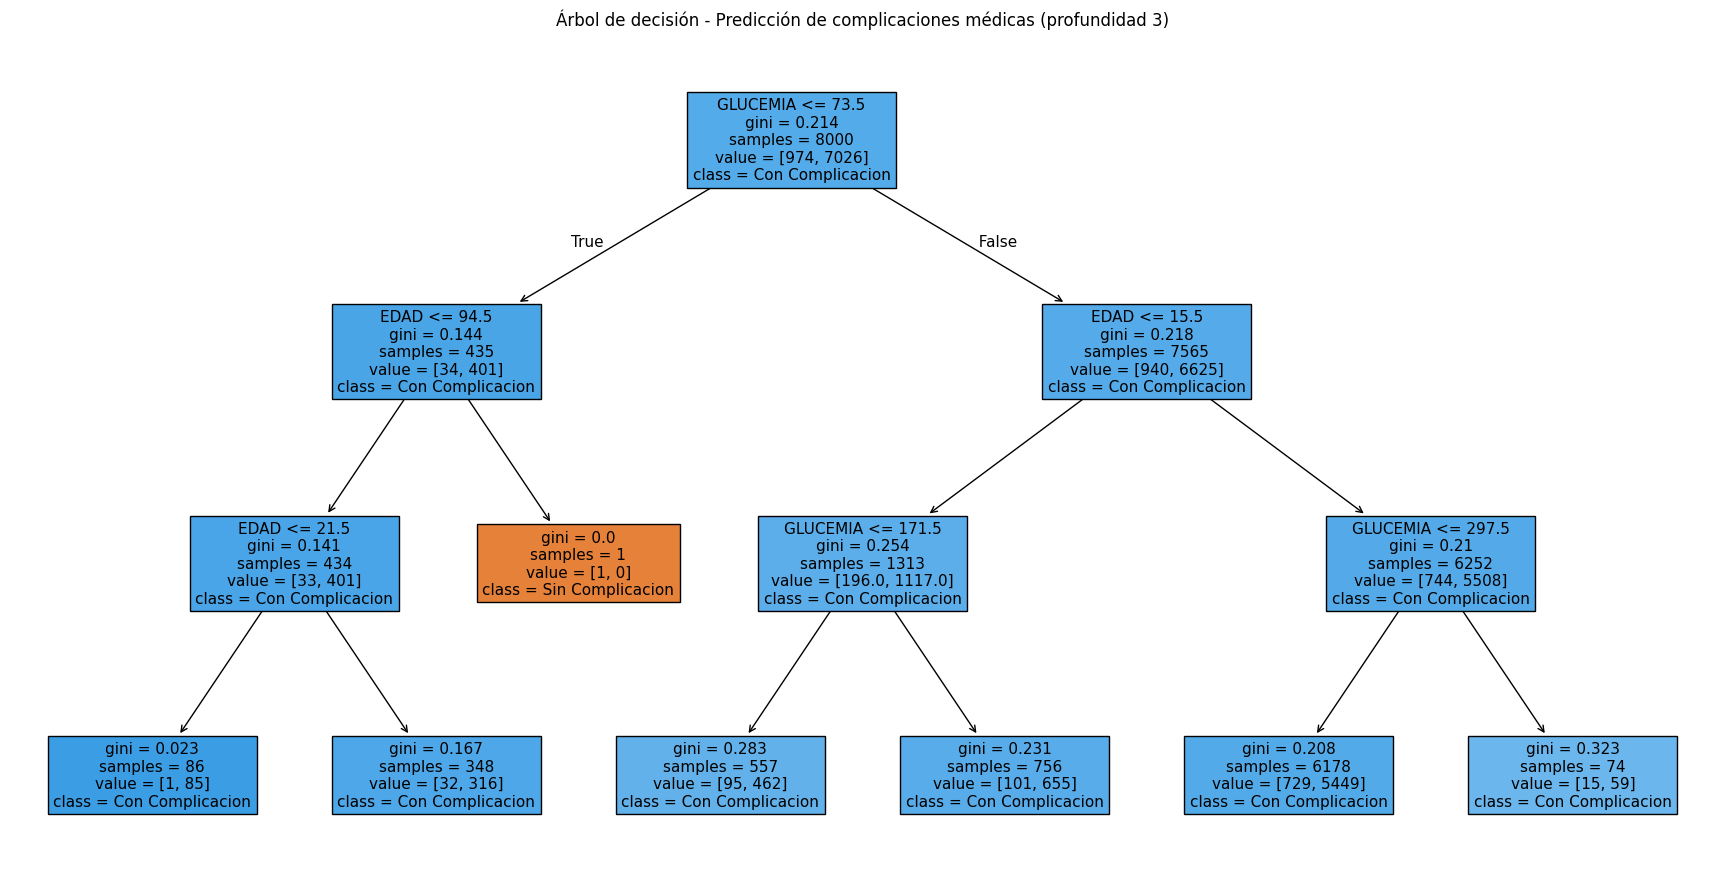

In [67]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 11))
plot_tree(
    modelo_ArbolDecisionClasif,
    filled=True,
    feature_names=X_train.columns,
    class_names=['Sin Complicacion', 'Con Complicacion'],
    fontsize=11
)
plt.title("Árbol de decisión - Predicción de complicaciones médicas (profundidad 3)")
plt.show()

In [68]:
from sklearn.tree import export_text

print(export_text(modelo_ArbolDecisionClasif,
                  feature_names=list(X_train.columns), show_weights=True))

|--- GLUCEMIA <= 73.50
|   |--- EDAD <= 94.50
|   |   |--- EDAD <= 21.50
|   |   |   |--- weights: [1.00, 85.00] class: 1
|   |   |--- EDAD >  21.50
|   |   |   |--- weights: [32.00, 316.00] class: 1
|   |--- EDAD >  94.50
|   |   |--- weights: [1.00, 0.00] class: 0
|--- GLUCEMIA >  73.50
|   |--- EDAD <= 15.50
|   |   |--- GLUCEMIA <= 171.50
|   |   |   |--- weights: [95.00, 462.00] class: 1
|   |   |--- GLUCEMIA >  171.50
|   |   |   |--- weights: [101.00, 655.00] class: 1
|   |--- EDAD >  15.50
|   |   |--- GLUCEMIA <= 297.50
|   |   |   |--- weights: [729.00, 5449.00] class: 1
|   |   |--- GLUCEMIA >  297.50
|   |   |   |--- weights: [15.00, 59.00] class: 1



In [69]:
paciente = X_test.iloc[[0]]
print("Paciente: EDAD =", int(paciente['EDAD'].iloc[0]),
      "| GLUCEMIA =", int(paciente['GLUCEMIA'].iloc[0]))

arbol = modelo_ArbolDecisionClasif.tree_
nombres = X_train.columns
nodos = modelo_ArbolDecisionClasif.decision_path(paciente).indices

for n in nodos:
    if arbol.children_left[n] != -1:    # nodo con regla de división
        var = nombres[arbol.feature[n]]
        valor = paciente[var].iloc[0]
        umbral = arbol.threshold[n]
        signo = "<=" if valor <= umbral else ">"
        print(f"Nodo {n}: {var} = {valor} {signo} {umbral:.1f}")
    else:
        sin, con = arbol.value[n][0]
        print(f"Hoja {n}: {int(arbol.n_node_samples[n])} pacientes de entrenamiento,",
              f"{con/(sin+con):.3f} con complicación")

print("Probabilidad de complicación:",
      modelo_ArbolDecisionClasif.predict_proba(paciente)[0, 1].round(4))

Paciente: EDAD = 49 | GLUCEMIA = 63
Nodo 0: GLUCEMIA = 63 <= 73.5
Nodo 1: EDAD = 49 <= 94.5
Nodo 2: EDAD = 49 > 21.5
Hoja 4: 348 pacientes de entrenamiento, 0.908 con complicación
Probabilidad de complicación: 0.908


In [70]:
hojas_train = modelo_ArbolDecisionClasif.apply(X_train)
hojas_test = modelo_ArbolDecisionClasif.apply(X_test)

resumen = pd.DataFrame({
    'pacientes_train': pd.Series(hojas_train).value_counts(),
    'prop_con_complicacion': y_train.groupby(hojas_train).mean().round(3),
    'pacientes_test': pd.Series(hojas_test).value_counts()
}).fillna(0).astype({'pacientes_train': int, 'pacientes_test': int})

resumen['clase_predicha'] = (resumen['prop_con_complicacion'] >= 0.5).astype(int)
print(resumen.sort_index())

    pacientes_train  prop_con_complicacion  pacientes_test  clase_predicha
3                86                  0.988              24               1
4               348                  0.908              91               1
5                 1                  0.000               0               0
8               557                  0.829             141               1
9               756                  0.866             182               1
11             6178                  0.882            1533               1
12               74                  0.797              29               1


**Visualización:** árbol de decisión (profundidad 3, 7 hojas) dibujado con `plot_tree`, con las reglas de cada nodo, el número de pacientes (`samples`), la distribución de clases (`value`) y la clase mayoritaria. También se imprimió en formato de texto con `export_text`.

**Ruta de decisión interpretada:** la ruta más recorrida es `GLUCEMIA > 73.5` → `EDAD > 15.5` → `GLUCEMIA <= 297.5`. Termina en una hoja con 6,178 pacientes de entrenamiento, 5,449 de ellos con complicación (88.2 %), y el modelo predice "con complicación". En conjunto, un paciente con glucemia entre 73.5 y 297.5 y edad mayor de 15.5 años, que es el 77 % de los pacientes de entrenamiento, recibe una probabilidad de complicación de 0.882, casi igual a la prevalencia del 87.8 %. Otro ejemplo: un paciente de 49 años y glucemia 63 sigue `GLUCEMIA <= 73.5` → `EDAD <= 94.5` → `EDAD > 21.5` y llega a una hoja con 348 pacientes (90.8 % con complicación).

**Qué aporta la visualización:**
- Permite explicar cada predicción con reglas simples ("si glucemia..., y edad..., entonces...") sin conocimientos de estadística.
- Muestra que el árbol solo usa `EDAD` y `GLUCEMIA`, lo que coincide con la importancia de la Pregunta 8.
- Deja ver el límite del modelo: las 7 hojas tienen porcentajes entre 80 % y 99 % de complicaciones, así que ninguna regla separa a los pacientes sanos; solo hay una hoja que predice "sin complicación", con un único paciente. Esto explica por qué el modelo clasifica a todos como "con complicación" (Pregunta 9).
- Es una señal para la siguiente iteración: hacen falta variables clínicas con más información para que las hojas se parezcan menos a la población general.